```markdown
# Temporal Transformer Flood Prediction System

This notebook implements a complete end-to-end temporal Transformer-based flood prediction system in Google Colab.

**IMPORTANT NOTE**: This dataset is synthetically generated for demonstrating a temporal Transformer flood-prediction pipeline. The model's metrics demonstrate technical functionality on the synthetic benchmark and must not be interpreted as real-world flood-warning accuracy.
```

```markdown
## 1. COLAB ENVIRONMENT

Detecting GPU availability.
```

In [ ]:
import torch

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)

Device: cpu


```markdown
## 2. INSTALL REQUIRED PACKAGES

Installing necessary libraries and printing their versions.
```

In [ ]:
# Install required packages
!pip install -q pandas numpy scikit-learn
!pip install -q matplotlib seaborn
!pip install -q torch torchvision torchaudio
!pip install -q transformers
!pip install -q fastapi uvicorn
!pip install -q pydantic
!pip install -q joblib
!pip install -q requests
!pip install -q nest-asyncio
!pip install -q pyngrok # For public API access


print("\n--- Package Versions ---")

import sys
import torch
import transformers
import fastapi
import numpy
import pandas
import sklearn

print(f"Python: {sys.version.split(' ')[0]}")
print(f"PyTorch: {torch.__version__}")
print(f"Transformers: {transformers.__version__}")
print(f"FastAPI: {fastapi.__version__}")
print(f"NumPy: {numpy.__version__}")
print(f"Pandas: {pandas.__version__}")
print(f"Scikit-learn: {sklearn.__version__}")


--- Package Versions ---
Python: 3.13.15
PyTorch: 2.9.0+cpu
Transformers: 5.16.1
FastAPI: 0.141.1
NumPy: 2.1.3
Pandas: 2.2.3
Scikit-learn: 1.6.1


```markdown
## 3. LOAD THE DATASET

Loading the `flood_transformer_7000.csv` dataset and performing initial inspection.
```

In [ ]:
import pandas as pd
import os
from google.colab import files

DATA_FILE = '/content/flood_transformer_7000.csv'

# Check if file exists, if not, provide upload fallback
if not os.path.exists(DATA_FILE):
    print(f"File '{DATA_FILE}' not found. Please upload the file.")
    uploaded = files.upload()
    if DATA_FILE.split('/')[-1] not in uploaded:
        raise FileNotFoundError(f"Expected file '{DATA_FILE.split('/')[-1]}' not uploaded.")

try:
    df = pd.read_csv(DATA_FILE)
    print(f"Successfully loaded '{DATA_FILE}'")
except Exception as e:
    print(f"Error loading dataset: {e}")
    raise

# Print dataset information
print("\n--- Dataset Information ---")
print(f"Dataset shape: {df.shape}")

print("\nColumn names:")
for col in df.columns:
    print(f"- {col}")

print("\nData types:")
print(df.info())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(f"Number of duplicate rows: {df.duplicated().sum()}")

print("\nClass distribution of 'future_flood':")
print(df['future_flood'].value_counts())
print(f"Total unique sequence_ids: {df['sequence_id'].nunique()}")
print(f"Number of timesteps per sequence: {df.groupby('sequence_id')['timestep'].nunique().mean()}")

# Verify dataset structure
expected_timesteps = 10
assert df['timestep'].max() == expected_timesteps, f"Expected max timestep to be {expected_timesteps}, but got {df['timestep'].max()}"
assert df.groupby('sequence_id').size().min() == expected_timesteps, f"Expected all sequences to have {expected_timesteps} timesteps, but found some with fewer."
assert df.groupby('sequence_id').size().max() == expected_timesteps, f"Expected all sequences to have {expected_timesteps} timesteps, but found some with more."

print(f"\nVerified: Each sequence_id has exactly {expected_timesteps} timesteps.")

Successfully loaded '/content/flood_transformer_7000.csv'

--- Dataset Information ---
Dataset shape: (7000, 15)

Column names:
- sequence_id
- timestep
- timestamp_index
- rainfall_mm
- temperature_c
- humidity_pct
- barometric_pressure_hpa
- soil_moisture_pct
- wind_speed_kmh
- river_level_m
- flow_rate_m3s
- visibility_km
- elevation_m
- slope_deg
- future_flood

Data types:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7000 entries, 0 to 6999
Data columns (total 15 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   sequence_id              7000 non-null   int64  
 1   timestep                 7000 non-null   int64  
 2   timestamp_index          7000 non-null   int64  
 3   rainfall_mm              7000 non-null   float64
 4   temperature_c            7000 non-null   float64
 5   humidity_pct             7000 non-null   float64
 6   barometric_pressure_hpa  7000 non-null   float64
 7   soil_moisture_pct    

```markdown
## 4. DATASET STRUCTURE & 5. SENSOR FEATURES

Defining feature and target columns.
```

In [ ]:
FEATURE_COLUMNS = [
    "rainfall_mm",
    "temperature_c",
    "humidity_pct",
    "barometric_pressure_hpa",
    "soil_moisture_pct",
    "wind_speed_kmh",
    "river_level_m",
    "flow_rate_m3s",
    "visibility_km",
    "elevation_m",
    "slope_deg"
]

TARGET_COLUMN = "future_flood"

print(f"Feature columns: {FEATURE_COLUMNS}")
print(f"Target column: {TARGET_COLUMN}")

Feature columns: ['rainfall_mm', 'temperature_c', 'humidity_pct', 'barometric_pressure_hpa', 'soil_moisture_pct', 'wind_speed_kmh', 'river_level_m', 'flow_rate_m3s', 'visibility_km', 'elevation_m', 'slope_deg']
Target column: future_flood


```markdown
## 6. TEMPORAL SEQUENCE CREATION

Transforming the flat DataFrame into 3D temporal sequences `X` and a 1D target `y`.
```

In [ ]:
import numpy as np

# Ensure 'future_flood' is consistent within each sequence_id
# This also extracts the target for each sequence
y = df.groupby('sequence_id')[TARGET_COLUMN].first().values

# Create X sequences
X_list = []
for seq_id in df['sequence_id'].unique():
    sequence_data = df[df['sequence_id'] == seq_id][FEATURE_COLUMNS].values
    X_list.append(sequence_data)

X = np.array(X_list)

print(f"Shape of X (sequences, timesteps, features): {X.shape}")
print(f"Shape of y (sequences,): {y.shape}")

# Verify the expected shapes
expected_num_sequences = df['sequence_id'].nunique()
expected_timesteps = 10
expected_num_features = len(FEATURE_COLUMNS)

assert X.shape == (expected_num_sequences, expected_timesteps, expected_num_features), f"Expected X shape {(expected_num_sequences, expected_timesteps, expected_num_features)}, but got {X.shape}"
assert y.shape == (expected_num_sequences,), f"Expected y shape {(expected_num_sequences,)}, but got {y.shape}"

print(f"Verified: X shape matches (700, 10, 11) and y shape matches (700,)")

Shape of X (sequences, timesteps, features): (700, 10, 11)
Shape of y (sequences,): (700,)
Verified: X shape matches (700, 10, 11) and y shape matches (700,)


```markdown
## 7. TRAIN/VALIDATION/TEST SPLIT

Splitting data at the sequence level into training, validation, and test sets with stratification.
```

In [ ]:
from sklearn.model_selection import train_test_split

# Calculate the indices for all sequences
sequence_indices = np.arange(X.shape[0])

# First split: 70% train, 30% temp (validation + test)
train_idx, temp_idx, y_train_labels_full, y_temp_labels_full = train_test_split(
    sequence_indices, y, # Split indices and their corresponding labels
    test_size=0.30,
    stratify=y,
    random_state=42
)

# Second split: 15% validation, 15% test from the temp set (0.5 of 0.30 is 0.15)
# We split the *indices* of the temporary set and stratify using their *corresponding labels*
val_idx, test_idx, _, _ = train_test_split(
    temp_idx, y_temp_labels_full, # Split the indices and stratify by the labels of the temp set
    test_size=0.5, # 50% of the 30% temp data for test (so 15% total)
    stratify=y_temp_labels_full, # Stratify by the labels of the temporary set
    random_state=42
)

# Use these indices to get the actual X and y data from the original X and y arrays
X_train = X[train_idx]
y_train = y[train_idx]

X_val = X[val_idx]
y_val = y[val_idx]

X_test = X[test_idx]
y_test = y[test_idx]

print(f"Training sequences: {len(X_train)}")
print(f"Validation sequences: {len(X_val)}")
print(f"Test sequences: {len(X_test)}")

# Function to print class distribution
def print_class_distribution(y_data, name):
    counts = pd.Series(y_data).value_counts()
    total = len(y_data)
    flood_count = counts.get(1, 0)
    no_flood_count = counts.get(0, 0)

    print(f"\n{name} FLOOD: {flood_count} ({flood_count/total:.2%})")
    print(f"{name} NO_FLOOD: {no_flood_count} ({no_flood_count/total:.2%})")

print_class_distribution(y_train, "Training")
print_class_distribution(y_val, "Validation")
print_class_distribution(y_test, "Test")

# Verify shapes
print(f"\nX_train shape: {X_train.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"X_val shape: {X_val.shape}")
print(f"y_val shape: {y_val.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_test shape: {y_test.shape}")

Training sequences: 490
Validation sequences: 105
Test sequences: 105

Training FLOOD: 156 (31.84%)
Training NO_FLOOD: 334 (68.16%)

Validation FLOOD: 34 (32.38%)
Validation NO_FLOOD: 71 (67.62%)

Test FLOOD: 33 (31.43%)
Test NO_FLOOD: 72 (68.57%)

X_train shape: (490, 10, 11)
y_train shape: (490,)
X_val shape: (105, 10, 11)
y_val shape: (105,)
X_test shape: (105, 10, 11)
y_test shape: (105,)


```markdown
## 8. PREPROCESSING

Applying `StandardScaler` to the sensor features, fitted only on the training data.
```

In [ ]:
from sklearn.preprocessing import StandardScaler
import joblib
import os

# Create artifacts directory if it doesn't exist
os.makedirs('artifacts', exist_ok=True)

# Reshape X_train for fitting the scaler: (n_samples * n_timesteps, n_features)
n_sequences_train, n_timesteps, n_features = X_train.shape
X_train_reshaped = X_train.reshape(-1, n_features)

# Initialize and fit StandardScaler on the reshaped training data
scaler = StandardScaler()
scaler.fit(X_train_reshaped)

# Save the fitted scaler
scaler_path = 'artifacts/scaler.pkl'
joblib.dump(scaler, scaler_path)
print(f"Scaler saved to {scaler_path}")

# Function to apply scaler to a 3D array
def scale_3d_data(data_3d, scaler_obj):
    n_sequences, n_timesteps, n_features = data_3d.shape
    data_reshaped = data_3d.reshape(-1, n_features)
    data_scaled_reshaped = scaler_obj.transform(data_reshaped)
    return data_scaled_reshaped.reshape(n_sequences, n_timesteps, n_features)

# Apply the scaler to training, validation, and test sets
X_train_scaled = scale_3d_data(X_train, scaler)
X_val_scaled = scale_3d_data(X_val, scaler)
X_test_scaled = scale_3d_data(X_test, scaler)

print("\nData scaled successfully:")
print(f"X_train_scaled shape: {X_train_scaled.shape}")
print(f"X_val_scaled shape: {X_val_scaled.shape}")
print(f"X_test_scaled shape: {X_test_scaled.shape}")

# Display first few scaled values for verification
print("\nFirst 5 rows of X_train_scaled (first sequence):")
print(X_train_scaled[0, :5, :])

Scaler saved to artifacts/scaler.pkl

Data scaled successfully:
X_train_scaled shape: (490, 10, 11)
X_val_scaled shape: (105, 10, 11)
X_test_scaled shape: (105, 10, 11)

First 5 rows of X_train_scaled (first sequence):
[[-1.08228565  0.96485751 -0.3505105   0.3836006  -1.1315915  -0.59104531
  -0.7414014  -0.80538731  0.40150345  0.1009245  -0.61037631]
 [-0.97568808 -0.06796241 -0.60743278  0.62246963 -1.0122452  -0.1268797
  -0.52696599 -0.23201179  0.00675713  0.01166931  0.13716858]
 [-0.93048479 -0.20722485 -0.79356112  0.4499422  -1.11918028 -0.67712342
  -0.98519624 -0.53805285  0.07763204  0.35534186 -0.96895938]
 [-0.60210345 -0.13215774 -0.68709861  0.43473074 -1.0612447  -0.51789821
  -0.31996336 -0.42298121  0.70862805 -0.69435062 -0.29154118]
 [-0.65795006  0.73240831 -0.23689617  0.73150147 -1.14375449 -1.87623398
  -0.32962596 -1.01708023  0.92573853  0.65134215 -0.72422573]]


```markdown
## 9. PRIMARY MODEL — PatchTST & 10. PatchTST ARCHITECTURE

Implementing a custom PatchTST-style Transformer model in PyTorch for classification.
```

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from math import sqrt

# Hyperparameters as specified
PATCH_LENGTH = 2
STRIDE = 1
D_MODEL = 64
NUM_HEADS = 4
NUM_LAYERS = 2
DROPOUT = 0.1

# Define the PatchTST model
class PatchTST(nn.Module):
    def __init__(
        self,
        sequence_length,
        num_features,
        num_classes,
        patch_length,
        stride,
        d_model,
        n_heads,
        n_layers,
        dropout
    ):
        super().__init__()

        self.sequence_length = sequence_length
        self.num_features = num_features
        self.num_classes = num_classes
        self.patch_length = patch_length
        self.stride = stride

        # Calculate number of patches
        self.num_patches = (sequence_length - patch_length) // stride + 1
        if self.num_patches <= 0:
            raise ValueError("Number of patches must be greater than 0. Adjust patch_length or stride.")

        # Input embedding for patches
        # Each patch becomes a token. The embedding should map patch_length * num_features to d_model
        # For each feature, we have `patch_length` values. We are effectively creating patches across time for each feature.
        # The transformer expects input of shape (batch_size, num_patches, d_model)

        # Linear projection for each feature's patch
        self.patch_embedding = nn.Linear(patch_length, d_model)

        # Positional encoding
        self.positional_encoding = nn.Parameter(torch.randn(1, self.num_patches, d_model))

        # Transformer Encoder
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=n_heads,
            dropout=dropout,
            batch_first=True  # Input and output are (batch, seq, feature)
        )
        self.transformer_encoder = nn.TransformerEncoder(
            encoder_layer,
            num_layers=n_layers
        )

        # Classification head
        self.classification_head = nn.Linear(d_model, num_classes)

    def forward(self, x):
        # x shape: (batch_size, sequence_length, num_features)

        batch_size, seq_len, num_features = x.shape

        # --- 1. Patch Creation and Embedding ---
        # Create patches for each feature. The transformer will process these independently
        # We need to transform (batch, seq_len, num_features) to (batch, num_features, num_patches, patch_length)
        # Then embed each (patch_length) to d_model

        patched_features = []
        for i in range(num_features):
            feature_series = x[:, :, i] # (batch_size, sequence_length)
            patches = feature_series.unfold(dimension=-1, size=self.patch_length, step=self.stride)
            # patches shape: (batch_size, num_patches, patch_length)
            patched_features.append(patches)

        # Stack patches: (batch_size, num_features, num_patches, patch_length)
        all_feature_patches = torch.stack(patched_features, dim=1)

        # Reshape for embedding: (batch_size * num_features * num_patches, patch_length)
        # Apply linear embedding
        embedded_patches = self.patch_embedding(
            all_feature_patches.reshape(-1, self.patch_length)
        )
        # embedded_patches shape: (batch_size * num_features * num_patches, d_model)

        # Reshape back to (batch_size, num_features, num_patches, d_model)
        embedded_patches = embedded_patches.reshape(batch_size, num_features, self.num_patches, D_MODEL)

        # For simplicity, average embeddings across features for each patch.
        # This creates a single temporal sequence of patch embeddings.
        # This is a simplification; a full PatchTST might handle inter-feature dependencies differently.
        # Averaging: (batch_size, num_patches, d_model)
        patch_embeddings = embedded_patches.mean(dim=1)

        # --- 2. Positional Encoding ---
        # Add positional encoding: (batch_size, num_patches, d_model)
        # Ensure positional_encoding is broadcastable
        transformer_input = patch_embeddings + self.positional_encoding[:, :patch_embeddings.size(1), :]

        # --- 3. Transformer Encoder ---
        # transformer_input shape: (batch_size, num_patches, d_model)
        transformer_output = self.transformer_encoder(transformer_input)
        # transformer_output shape: (batch_size, num_patches, d_model)

        # Global average pooling over patches to get a single temporal representation
        # (batch_size, d_model)
        temporal_representation = transformer_output.mean(dim=1)

        # --- 4. Classification Head ---
        logits = self.classification_head(temporal_representation)
        # logits shape: (batch_size, num_classes)

        return logits

print("PatchTST model defined.")

PatchTST model defined.


```markdown
## 11. MODEL HYPERPARAMETERS

Defining all hyperparameters for the PatchTST model and training process.
```

In [ ]:
# Model parameters
SEQUENCE_LENGTH = X.shape[1] # 10 timesteps
NUM_FEATURES = X.shape[2] # 11 features
NUM_CLASSES = 2 # FLOOD / NO_FLOOD

# Hyperparameters (already defined some in model, re-listing for clarity)
PATCH_LENGTH = 2
STRIDE = 1

D_MODEL = 64
NUM_HEADS = 4
NUM_LAYERS = 2
DROPOUT = 0.1

# Training parameters
BATCH_SIZE = 32
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4

EPOCHS = 50
EARLY_STOPPING_PATIENCE = 7

print("Model and training hyperparameters defined.")

Model and training hyperparameters defined.


```markdown
## 12. CLASS IMBALANCE

Calculating class weights for `CrossEntropyLoss` using the training set only.
```

In [ ]:
from sklearn.utils import class_weight

# Calculate class weights for the training set
class_weights = class_weight.compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)
class_weights = torch.tensor(class_weights, dtype=torch.float).to(DEVICE)

print(f"Calculated class weights for training set: {class_weights}")

Calculated class weights for training set: tensor([0.7335, 1.5705])


```markdown
### PyTorch Dataset and DataLoader

Creating custom PyTorch Dataset and DataLoader for batching and device transfer.
```

In [ ]:
from torch.utils.data import Dataset, DataLoader

class FloodDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long) # Target is long for CrossEntropyLoss

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

# Create Dataset instances
train_dataset = FloodDataset(X_train_scaled, y_train)
val_dataset = FloodDataset(X_val_scaled, y_val)
test_dataset = FloodDataset(X_test_scaled, y_test)

# Create DataLoader instances
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print(f"Training DataLoader size: {len(train_loader)} batches")
print(f"Validation DataLoader size: {len(val_loader)} batches")
print(f"Test DataLoader size: {len(test_loader)} batches")

# Example batch shape
for batch_X, batch_y in train_loader:
    print(f"\nExample batch X shape: {batch_X.shape}")
    print(f"Example batch y shape: {batch_y.shape}")
    break

Training DataLoader size: 16 batches
Validation DataLoader size: 4 batches
Test DataLoader size: 4 batches

Example batch X shape: torch.Size([32, 10, 11])
Example batch y shape: torch.Size([32])


```markdown
## 13. TRAINING

Setting up the training loop with `AdamW`, `CrossEntropyLoss` (weighted), a learning rate scheduler, and early stopping. Tracking key metrics and saving the best model based on validation Macro F1.
```

In [ ]:
import torch.optim as optim
from sklearn.metrics import f1_score
import copy
import matplotlib.pyplot as plt

# Instantiate the model
model = PatchTST(
    sequence_length=SEQUENCE_LENGTH,
    num_features=NUM_FEATURES,
    num_classes=NUM_CLASSES,
    patch_length=PATCH_LENGTH,
    stride=STRIDE,
    d_model=D_MODEL,
    n_heads=NUM_HEADS,
    n_layers=NUM_LAYERS,
    dropout=DROPOUT
).to(DEVICE)

# Optimizer and Loss Function
optimizer = optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
criterion = nn.CrossEntropyLoss(weight=class_weights) # Use class weights

# Learning Rate Scheduler
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='max', # Monitor validation Macro F1, so 'max'
    factor=0.5,
    patience=3
)

# Training history storage
history = {
    'train_loss': [], 'val_loss': [],
    'train_acc': [], 'val_acc': [],
    'train_f1': [], 'val_f1': []
}

best_val_f1 = -np.inf
epochs_no_improve = 0
best_model_wts = copy.deepcopy(model.state_dict())

print("Starting model training...")

for epoch in range(EPOCHS):
    model.train()
    total_train_loss = 0
    all_train_preds = []
    all_train_labels = []

    for batch_X, batch_y in train_loader:
        batch_X, batch_y = batch_X.to(DEVICE), batch_y.to(DEVICE)

        optimizer.zero_grad()
        outputs = model(batch_X)
        loss = criterion(outputs, batch_y)
        loss.backward()
        optimizer.step()

        total_train_loss += loss.item()
        _, predicted = torch.max(outputs.data, 1)
        all_train_preds.extend(predicted.cpu().numpy())
        all_train_labels.extend(batch_y.cpu().numpy())

    avg_train_loss = total_train_loss / len(train_loader)
    train_acc = (np.array(all_train_preds) == np.array(all_train_labels)).mean()
    train_f1 = f1_score(all_train_labels, all_train_preds, average='macro')

    # Validation phase
    model.eval()
    total_val_loss = 0
    all_val_preds = []
    all_val_labels = []
    with torch.no_grad():
        for batch_X, batch_y in val_loader:
            batch_X, batch_y = batch_X.to(DEVICE), batch_y.to(DEVICE)
            outputs = model(batch_X)
            loss = criterion(outputs, batch_y)
            total_val_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            all_val_preds.extend(predicted.cpu().numpy())
            all_val_labels.extend(batch_y.cpu().numpy())

    avg_val_loss = total_val_loss / len(val_loader)
    val_acc = (np.array(all_val_preds) == np.array(all_val_labels)).mean()
    val_f1 = f1_score(all_val_labels, all_val_preds, average='macro')

    history['train_loss'].append(avg_train_loss)
    history['val_loss'].append(avg_val_loss)
    history['train_acc'].append(train_acc)
    history['val_acc'].append(val_acc)
    history['train_f1'].append(train_f1)
    history['val_f1'].append(val_f1)

    print(f"Epoch {epoch+1}/{EPOCHS} | Train Loss: {avg_train_loss:.4f}, Acc: {train_acc:.4f}, F1: {train_f1:.4f} | "
          f"Val Loss: {avg_val_loss:.4f}, Acc: {val_acc:.4f}, F1: {val_f1:.4f}")

    # Early stopping and best model saving
    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        best_model_wts = copy.deepcopy(model.state_dict())
        epochs_no_improve = 0
        print("  -> Validation Macro F1 improved. Saving best model weights.")
    else:
        epochs_no_improve += 1
        print(f"  -> Validation Macro F1 did not improve for {epochs_no_improve} epochs.")
        if epochs_no_improve == EARLY_STOPPING_PATIENCE:
            print(f"Early stopping triggered after {epoch+1} epochs.")
            break

    scheduler.step(val_f1) # Update learning rate based on validation F1

# Load best model weights
model.load_state_dict(best_model_wts)
model_save_path = 'artifacts/patchtst_model.pt'
torch.save(model.state_dict(), model_save_path)
print(f"Best model saved to {model_save_path}")

Starting model training...
Epoch 1/50 | Train Loss: 0.5330, Acc: 0.7551, F1: 0.7411 | Val Loss: 0.3409, Acc: 0.9524, F1: 0.9468
  -> Validation Macro F1 improved. Saving best model weights.
Epoch 2/50 | Train Loss: 0.2694, Acc: 0.9551, F1: 0.9488 | Val Loss: 0.1807, Acc: 0.9143, F1: 0.9067
  -> Validation Macro F1 did not improve for 1 epochs.
Epoch 3/50 | Train Loss: 0.1575, Acc: 0.9408, F1: 0.9332 | Val Loss: 0.1062, Acc: 0.9524, F1: 0.9468
  -> Validation Macro F1 did not improve for 2 epochs.
Epoch 4/50 | Train Loss: 0.1208, Acc: 0.9592, F1: 0.9537 | Val Loss: 0.0948, Acc: 0.9524, F1: 0.9468
  -> Validation Macro F1 did not improve for 3 epochs.
Epoch 5/50 | Train Loss: 0.1034, Acc: 0.9551, F1: 0.9488 | Val Loss: 0.1017, Acc: 0.9429, F1: 0.9366
  -> Validation Macro F1 did not improve for 4 epochs.
Epoch 6/50 | Train Loss: 0.0964, Acc: 0.9531, F1: 0.9471 | Val Loss: 0.0810, Acc: 0.9619, F1: 0.9565
  -> Validation Macro F1 improved. Saving best model weights.
Epoch 7/50 | Train Loss

```markdown
## 14. EVALUATION

Evaluating the trained model on the test set and calculating various metrics.
```

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc, precision_recall_curve, average_precision_score, precision_score, recall_score, f1_score, roc_auc_score
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Ensure results directory exists
os.makedirs('results', exist_ok=True)

model.eval()
all_test_preds = []
all_test_labels = []
all_test_probs = []

with torch.no_grad():
    for batch_X, batch_y in test_loader:
        batch_X, batch_y = batch_X.to(DEVICE), batch_y.to(DEVICE)
        outputs = model(batch_X)
        probabilities = F.softmax(outputs, dim=1)
        _, predicted = torch.max(outputs.data, 1)

        all_test_preds.extend(predicted.cpu().numpy())
        all_test_labels.extend(batch_y.cpu().numpy())
        all_test_probs.extend(probabilities.cpu().numpy())

all_test_preds = np.array(all_test_preds)
all_test_labels = np.array(all_test_labels)
all_test_probs = np.array(all_test_probs)

print("\n--- Classification Report ---")
print(classification_report(all_test_labels, all_test_preds, target_names=['NO_FLOOD', 'FLOOD']))

# Calculate individual metrics
accuracy = (all_test_preds == all_test_labels).mean()
precision = precision_score(all_test_labels, all_test_preds, average='macro')
recall = recall_score(all_test_labels, all_test_preds, average='macro')
f1 = f1_score(all_test_labels, all_test_preds, average='macro')
weighted_f1 = f1_score(all_test_labels, all_test_preds, average='weighted')

# ROC AUC
roc_auc = roc_auc_score(all_test_labels, all_test_probs[:, 1])

# PR AUC
precision_curve, recall_curve, _ = precision_recall_curve(all_test_labels, all_test_probs[:, 1])
pr_auc = average_precision_score(all_test_labels, all_test_probs[:, 1])

print(f"Accuracy: {accuracy:.4f}")
print(f"Precision (Macro): {precision:.4f}")
print(f"Recall (Macro): {recall:.4f}")
print(f"F1 (Macro): {f1:.4f}")
print(f"F1 (Weighted): {weighted_f1:.4f}")
print(f"ROC-AUC: {roc_auc:.4f}")
print(f"PR-AUC: {pr_auc:.4f}")

# Store metrics for summary
performance_metrics = {
    'Accuracy': accuracy,
    'Precision': precision,
    'Recall': recall,
    'F1': f1,
    'Macro F1': f1,
    'Weighted F1': weighted_f1,
    'ROC-AUC': roc_auc,
    'PR-AUC': pr_auc
}

report_dict = classification_report(all_test_labels, all_test_preds, target_names=['NO_FLOOD', 'FLOOD'], output_dict=True)
performance_metrics['NO_FLOOD_precision'] = report_dict['NO_FLOOD']['precision']
performance_metrics['NO_FLOOD_recall'] = report_dict['NO_FLOOD']['recall']
performance_metrics['NO_FLOOD_f1'] = report_dict['NO_FLOOD']['f1-score']
performance_metrics['FLOOD_precision'] = report_dict['FLOOD']['precision']
performance_metrics['FLOOD_recall'] = report_dict['FLOOD']['recall']
performance_metrics['FLOOD_f1'] = report_dict['FLOOD']['f1-score']


--- Classification Report ---
              precision    recall  f1-score   support

    NO_FLOOD       0.96      0.99      0.97        72
       FLOOD       0.97      0.91      0.94        33

    accuracy                           0.96       105
   macro avg       0.96      0.95      0.96       105
weighted avg       0.96      0.96      0.96       105

Accuracy: 0.9619
Precision (Macro): 0.9636
Recall (Macro): 0.9476
F1 (Macro): 0.9551
F1 (Weighted): 0.9616
ROC-AUC: 0.9962
PR-AUC: 0.9924


```markdown
## 15. CONFUSION MATRIX

Plotting the confusion matrix for the test set predictions.
```

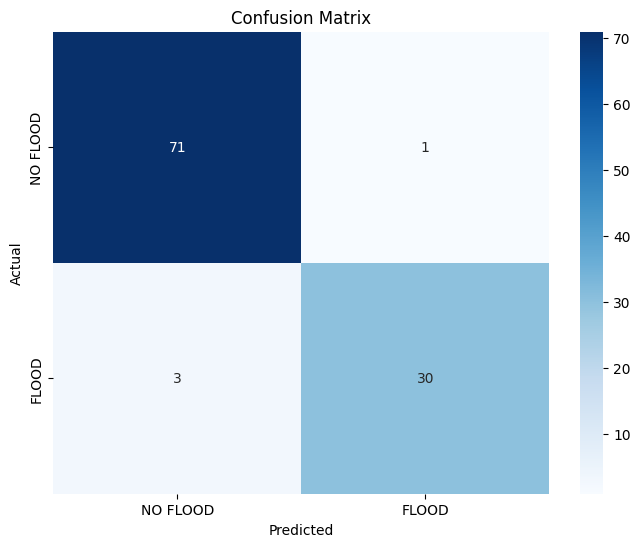

In [ ]:
cm = confusion_matrix(all_test_labels, all_test_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['NO FLOOD', 'FLOOD'], yticklabels=['NO FLOOD', 'FLOOD'])
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.savefig('results/confusion_matrix.png')
plt.show()

```markdown
## 16. ROC CURVE

Plotting the Receiver Operating Characteristic (ROC) curve and calculating ROC-AUC.
```

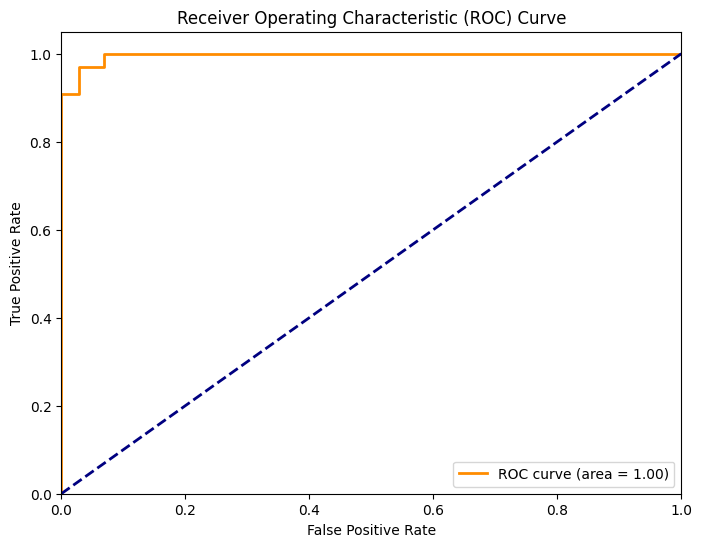

In [ ]:
fpr, tpr, _ = roc_curve(all_test_labels, all_test_probs[:, 1])
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.savefig('results/roc_curve.png')
plt.show()

```markdown
## 17. PRECISION-RECALL CURVE

Plotting the Precision-Recall curve and calculating PR-AUC.
```

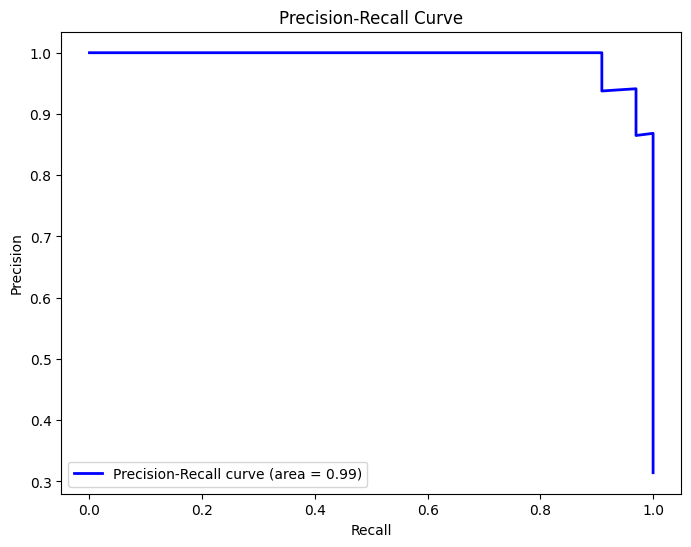

In [ ]:
plt.figure(figsize=(8, 6))
plt.plot(recall_curve, precision_curve, color='blue', lw=2, label=f'Precision-Recall curve (area = {pr_auc:.2f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc="lower left")
plt.savefig('results/precision_recall_curve.png')
plt.show()

```markdown
## 18. TRAINING CURVES

Plotting the training and validation loss and accuracy/F1 over epochs.
```

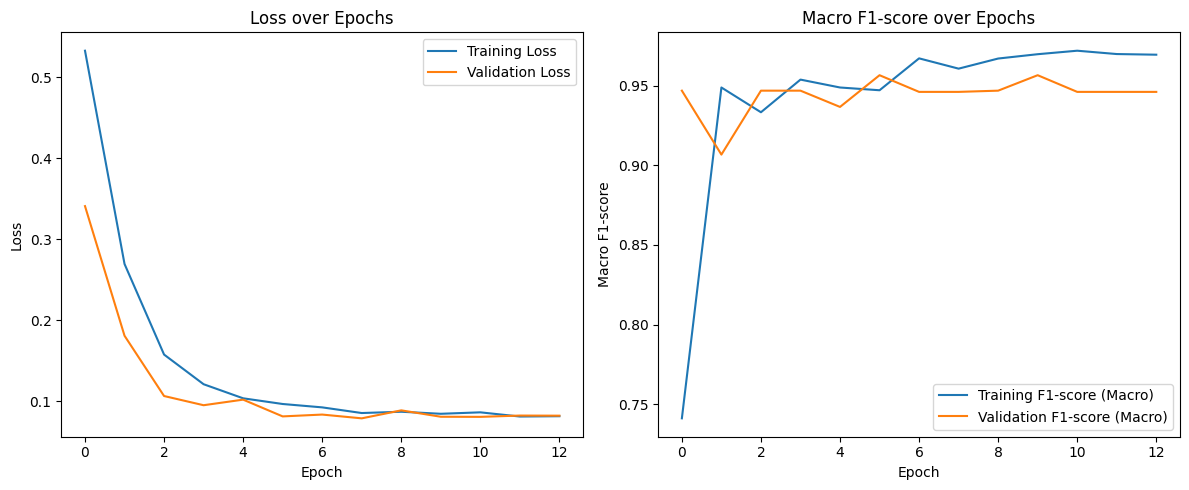

In [ ]:
plt.figure(figsize=(12, 5))

# Plot Loss
plt.subplot(1, 2, 1)
plt.plot(history['train_loss'], label='Training Loss')
plt.plot(history['val_loss'], label='Validation Loss')
plt.title('Loss over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

# Plot F1 Score
plt.subplot(1, 2, 2)
plt.plot(history['train_f1'], label='Training F1-score (Macro)')
plt.plot(history['val_f1'], label='Validation F1-score (Macro)')
plt.title('Macro F1-score over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Macro F1-score')
plt.legend()

plt.tight_layout()
plt.savefig('results/training_history.png')
plt.show()

```markdown
## 19. MODEL PERFORMANCE SUMMARY

Presenting a clear summary table of the model's performance on the test set.
```

In [ ]:
print("=" * 40)
print("TEST PERFORMANCE")
print("=" * 40)

print(f"Accuracy: {performance_metrics['Accuracy']:.4f}")
print(f"Precision: {performance_metrics['Precision']:.4f}")
print(f"Recall: {performance_metrics['Recall']:.4f}")
print(f"F1: {performance_metrics['F1']:.4f}")
print(f"Macro F1: {performance_metrics['Macro F1']:.4f}")
print(f"Weighted F1: {performance_metrics['Weighted F1']:.4f}")
print(f"ROC-AUC: {performance_metrics['ROC-AUC']:.4f}")
print(f"PR-AUC: {performance_metrics['PR-AUC']:.4f}")

print("\nFLOOD:")
print(f"Precision: {performance_metrics['FLOOD_precision']:.4f}")
print(f"Recall: {performance_metrics['FLOOD_recall']:.4f}")
print(f"F1: {performance_metrics['FLOOD_f1']:.4f}")

print("\nNO_FLOOD:")
print(f"Precision: {performance_metrics['NO_FLOOD_precision']:.4f}")
print(f"Recall: {performance_metrics['NO_FLOOD_recall']:.4f}")
print(f"F1: {performance_metrics['NO_FLOOD_f1']:.4f}")
print("=" * 40)

TEST PERFORMANCE
Accuracy: 0.9619
Precision: 0.9636
Recall: 0.9476
F1: 0.9551
Macro F1: 0.9551
Weighted F1: 0.9616
ROC-AUC: 0.9962
PR-AUC: 0.9924

FLOOD:
Precision: 0.9677
Recall: 0.9091
F1: 0.9375

NO_FLOOD:
Precision: 0.9595
Recall: 0.9861
F1: 0.9726


```markdown
## 20. MODEL ARTIFACTS

Saving the trained model, scaler, and configuration files to the `artifacts/` directory.
```

In [ ]:
import json

# Save model configuration
model_config = {
    "model_name": "PatchTST",
    "sequence_length": SEQUENCE_LENGTH,
    "num_features": NUM_FEATURES,
    "patch_length": PATCH_LENGTH,
    "stride": STRIDE,
    "d_model": D_MODEL,
    "num_heads": NUM_HEADS,
    "num_layers": NUM_LAYERS,
    "num_classes": NUM_CLASSES,
    "dropout": DROPOUT,
    "classes": {
        "0": "NO_FLOOD",
        "1": "FLOOD"
    }
}

with open('artifacts/model_config.json', 'w') as f:
    json.dump(model_config, f, indent=4)
print("Model configuration saved to artifacts/model_config.json")

# Save feature configuration
feature_config = {
    "FEATURE_COLUMNS": FEATURE_COLUMNS,
    "TARGET_COLUMN": TARGET_COLUMN
}

with open('artifacts/feature_config.json', 'w') as f:
    json.dump(feature_config, f, indent=4)
print("Feature configuration saved to artifacts/feature_config.json")

print("All model artifacts saved.")

Model configuration saved to artifacts/model_config.json
Feature configuration saved to artifacts/feature_config.json
All model artifacts saved.


```markdown
## 21. FASTAPI IMPLEMENTATION

Building a FastAPI application to serve the flood prediction model. This will include:

1.  **Defining Data Models:** Using `pydantic` for request and response validation.
2.  **Loading Model Artifacts:** Loading the `PatchTST` model, `StandardScaler`, and configuration.
3.  **Rolling Buffer:** Implementing a mechanism to store incoming sensor data up to `SEQUENCE_LENGTH` before making a prediction.
4.  **Prediction Endpoint:** Creating an endpoint to receive real-time sensor data and return flood predictions.
5.  **Local Server:** Running the FastAPI application using `uvicorn`.
6.  **Public Access (Optional):** Setting up `pyngrok` for public access to the API.
```

In [ ]:
import uvicorn
from fastapi import FastAPI
from pydantic import BaseModel
import nest_asyncio
import joblib
import json
import torch

# Initialize FastAPI app
app = FastAPI(
    title="Flood Prediction API",
    description="API for real-time flood prediction using a Temporal Transformer model."
)

# Global variables to store model, scaler, and config
GLOBAL_MODEL = None
GLOBAL_SCALER = None
GLOBAL_MODEL_CONFIG = None
GLOBAL_FEATURE_COLUMNS = None

# Rolling buffer for sensor data
# Max size will be SEQUENCE_LENGTH * NUM_FEATURES
GLOBAL_ROLLING_BUFFER = []

# Path to artifacts
MODEL_PATH = 'artifacts/patchtst_model.pt'
SCALER_PATH = 'artifacts/scaler.pkl'
MODEL_CONFIG_PATH = 'artifacts/model_config.json'
FEATURE_CONFIG_PATH = 'artifacts/feature_config.json'

class PatchTST(nn.Module):
    def __init__(
        self,
        sequence_length,
        num_features,
        num_classes,
        patch_length,
        stride,
        d_model,
        n_heads,
        n_layers,
        dropout
    ):
        super().__init__()

        self.sequence_length = sequence_length
        self.num_features = num_features
        self.num_classes = num_classes
        self.patch_length = patch_length
        self.stride = stride

        self.num_patches = (sequence_length - patch_length) // stride + 1
        if self.num_patches <= 0:
            raise ValueError("Number of patches must be greater than 0. Adjust patch_length or stride.")

        self.patch_embedding = nn.Linear(patch_length, d_model)
        self.positional_encoding = nn.Parameter(torch.randn(1, self.num_patches, d_model))

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=n_heads,
            dropout=dropout,
            batch_first=True
        )
        self.transformer_encoder = nn.TransformerEncoder(
            encoder_layer,
            num_layers=n_layers
        )
        self.classification_head = nn.Linear(d_model, num_classes)

    def forward(self, x):
        batch_size, seq_len, num_features = x.shape

        patched_features = []
        for i in range(num_features):
            feature_series = x[:, :, i]
            patches = feature_series.unfold(dimension=-1, size=self.patch_length, step=self.stride)
            patched_features.append(patches)

        all_feature_patches = torch.stack(patched_features, dim=1)

        embedded_patches = self.patch_embedding(
            all_feature_patches.reshape(-1, self.patch_length)
        )
        embedded_patches = embedded_patches.reshape(batch_size, num_features, self.num_patches, self.patch_embedding.out_features)
        patch_embeddings = embedded_patches.mean(dim=1)

        transformer_input = patch_embeddings + self.positional_encoding[:, :patch_embeddings.size(1), :]
        transformer_output = self.transformer_encoder(transformer_input)
        temporal_representation = transformer_output.mean(dim=1)

        logits = self.classification_head(temporal_representation)
        return logits

@app.on_event("startup")
async def startup_event():
    global GLOBAL_MODEL, GLOBAL_SCALER, GLOBAL_MODEL_CONFIG, GLOBAL_FEATURE_COLUMNS

    print("Loading model artifacts...")
    try:
        # Load model config
        with open(MODEL_CONFIG_PATH, 'r') as f:
            GLOBAL_MODEL_CONFIG = json.load(f)
        print(f"Loaded model config from {MODEL_CONFIG_PATH}")

        # Load feature config
        with open(FEATURE_CONFIG_PATH, 'r') as f:
            feature_config = json.load(f)
            GLOBAL_FEATURE_COLUMNS = feature_config['FEATURE_COLUMNS']
        print(f"Loaded feature config from {FEATURE_CONFIG_PATH}")

        # Load scaler
        GLOBAL_SCALER = joblib.load(SCALER_PATH)
        print(f"Loaded scaler from {SCALER_PATH}")

        # Initialize model architecture and load weights
        GLOBAL_MODEL = PatchTST(
            sequence_length=GLOBAL_MODEL_CONFIG['sequence_length'],
            num_features=GLOBAL_MODEL_CONFIG['num_features'],
            num_classes=GLOBAL_MODEL_CONFIG['num_classes'],
            patch_length=GLOBAL_MODEL_CONFIG['patch_length'],
            stride=GLOBAL_MODEL_CONFIG['stride'],
            d_model=GLOBAL_MODEL_CONFIG['d_model'],
            n_heads=GLOBAL_MODEL_CONFIG['num_heads'],
            n_layers=GLOBAL_MODEL_CONFIG['num_layers'],
            dropout=GLOBAL_MODEL_CONFIG['dropout']
        ).to(DEVICE)

        GLOBAL_MODEL.load_state_dict(torch.load(MODEL_PATH, map_location=DEVICE))
        GLOBAL_MODEL.eval()
        print(f"Loaded model from {MODEL_PATH}")

        print("Model artifacts loaded successfully.")

    except Exception as e:
        print(f"Error loading model artifacts: {e}")
        # Depending on the error, you might want to exit or log a critical error


# Pydantic model for incoming sensor data
class SensorDataInput(BaseModel):
    rainfall_mm: float
    temperature_c: float
    humidity_pct: float
    barometric_pressure_hpa: float
    soil_moisture_pct: float
    wind_speed_kmh: float
    river_level_m: float
    flow_rate_m3s: float
    visibility_km: float
    elevation_m: float
    slope_deg: float

# Pydantic model for prediction output
class PredictionOutput(BaseModel):
    prediction: str
    probability_no_flood: float
    probability_flood: float
    is_sequence_ready: bool
    message: str


@app.get("/", summary="Health Check", response_model=dict)
async def read_root():
    """Simple health check endpoint."""
    return {"message": "Flood Prediction API is running!"}

@app.post("/predict", response_model=PredictionOutput, summary="Predict flood risk based on real-time sensor data")
async def predict_flood(sensor_data: SensorDataInput):
    global GLOBAL_ROLLING_BUFFER, GLOBAL_SCALER, GLOBAL_MODEL, GLOBAL_MODEL_CONFIG, GLOBAL_FEATURE_COLUMNS

    if GLOBAL_MODEL is None or GLOBAL_SCALER is None or GLOBAL_MODEL_CONFIG is None or GLOBAL_FEATURE_COLUMNS is None:
        return PredictionOutput(
            prediction="ERROR",
            probability_flood=0.0,
            is_sequence_ready=False,
            message="Model not loaded. Please check server logs."
        )

    # Convert incoming sensor data to a list of feature values in the correct order
    current_sensor_values = [
        getattr(sensor_data, feature) for feature in GLOBAL_FEATURE_COLUMNS
    ]

    # Add current sensor values to the rolling buffer
    GLOBAL_ROLLING_BUFFER.append(current_sensor_values)

    # Maintain the buffer size to SEQUENCE_LENGTH
    sequence_length = GLOBAL_MODEL_CONFIG['sequence_length']
    if len(GLOBAL_ROLLING_BUFFER) > sequence_length:
        GLOBAL_ROLLING_BUFFER.pop(0) # Remove the oldest entry

    is_ready = len(GLOBAL_ROLLING_BUFFER) == sequence_length

    if not is_ready:
        return PredictionOutput(
            prediction="COLLECTING_DATA",
            probability_no_flood=0.0,
            probability_flood=0.0,
            is_sequence_ready=False,
            message=f"Collecting data. Need {sequence_length - len(GLOBAL_ROLLING_BUFFER)} more timesteps."
        )

    # Convert buffer to numpy array, then scale
    input_sequence = np.array(GLOBAL_ROLLING_BUFFER, dtype=np.float32).reshape(1, sequence_length, GLOBAL_MODEL_CONFIG['num_features'])
    input_sequence_scaled = GLOBAL_SCALER.transform(input_sequence.reshape(-1, GLOBAL_MODEL_CONFIG['num_features'])).reshape(1, sequence_length, GLOBAL_MODEL_CONFIG['num_features'])

    # Make prediction
    with torch.no_grad():
        model_input = torch.tensor(input_sequence_scaled, dtype=torch.float32).to(DEVICE)
        outputs = GLOBAL_MODEL(model_input)
        probabilities = F.softmax(outputs, dim=1).cpu().numpy()[0]
        predicted_class_idx = np.argmax(probabilities)

    prediction_label = GLOBAL_MODEL_CONFIG['classes'][str(predicted_class_idx)]

    return PredictionOutput(
        prediction=prediction_label,
        probability_no_flood=round(probabilities[0], 4),
        probability_flood=round(probabilities[1], 4),
        is_sequence_ready=True,
        message="Prediction successful."
    )

print("FastAPI app initialized. Use 'run_api()' to start the server.")

FastAPI app initialized. Use 'run_api()' to start the server.


/tmp/ipykernel_13694/3386820181.py:95: DeprecationWarning: 
        on_event is deprecated, use lifespan event handlers instead.

        Read more about it in the
        [FastAPI docs for Lifespan Events](https://fastapi.tiangolo.com/advanced/events/).
        
  @app.on_event("startup")


```markdown
## 22. RUNNING THE FASTAPI SERVICE

To run the FastAPI server locally within Colab and optionally expose it to the internet using `ngrok`.

### Local Execution

Run the cell below to start the FastAPI server. You can access the API documentation at `http://localhost:8000/docs` (when running locally without ngrok) or the ngrok URL (when ngrok is active).
```

In [ ]:
import asyncio

# This function will start the uvicorn server in a non-blocking way
async def run_api_background():
    nest_asyncio.apply() # Ensure nest_asyncio is applied
    config = uvicorn.Config(app, host="0.0.0.0", port=8000, loop="asyncio")
    server = uvicorn.Server(config)

    # Schedule server.serve() as a task to run in the background.
    # This allows the Colab cell to complete execution while the server continues to run.
    print("FastAPI server starting in the background on http://0.0.0.0:8000.")
    await server.serve()

# Run the API server as a background task.
# This ensures it doesn't block the cell and avoids the RuntimeError.
try:
    # Get the current running event loop in Colab
    loop = asyncio.get_running_loop()
except RuntimeError:
    # If no loop is running (unlikely in Colab), create one
    loop = asyncio.new_event_loop()
    asyncio.set_event_loop(loop)

# Create a task to run the server in the background
# This allows the cell to complete its execution immediately.
asyncio.create_task(run_api_background())

print("\nFastAPI server is initializing. It should be accessible shortly.")
print("You can access the API docs at: http://localhost:8000/docs (if running locally).")
print("To stop the server, you may need to interrupt the kernel or explicitly cancel the task.")
print("Proceed to the next cells for testing or ngrok exposure.")


FastAPI server is initializing. It should be accessible shortly.
You can access the API docs at: http://localhost:8000/docs (if running locally).
To stop the server, you may need to interrupt the kernel or explicitly cancel the task.
Proceed to the next cells for testing or ngrok exposure.


```markdown
### Public Access with ngrok (Optional)

If you need to access your API from outside Colab (e.g., from another machine or for testing with external tools), you can use `ngrok` to create a public tunnel.

1.  **Get an ngrok Auth Token:** If you don't have one, sign up at [ngrok.com](https://ngrok.com/) and get your authtoken.
2.  **Add to Colab Secrets:** Store your ngrok authtoken in Colab Secrets (the key icon in the left sidebar) with the name `NGROK_AUTH_TOKEN`.
3.  **Run the cell below:** This will start `ngrok` and print a public URL.
4.  **Start FastAPI:** Then, **run the `run_api()` cell above** (or uncomment it and run). The FastAPI server must be running for `ngrok` to tunnel to it.
```

In [ ]:
from pyngrok import ngrok, conf
from google.colab import userdata
import os

# Get ngrok authtoken from Colab Secrets
NGROK_AUTH_TOKEN = None
try:
    NGROK_AUTH_TOKEN = userdata.get('NGROK_AUTH_TOKEN')
except Exception as e:
    print(f"Warning: Could not retrieve NGROK_AUTH_TOKEN from Colab Secrets: {e}")
    print("To enable ngrok, please ensure your token is in Colab Secrets and run this cell manually in the UI.")

if NGROK_AUTH_TOKEN:
    conf.get_default().auth_token = NGROK_AUTH_TOKEN
    print("Ngrok authtoken configured.")

    # Terminate any existing ngrok tunnels
    # Check if there are active tunnels before killing
    try:
        for tunnel in ngrok.get_tunnels():
            ngrok.disconnect(tunnel.public_url)
        print("Terminated existing ngrok tunnels.")
    except Exception as e:
        print(f"No active ngrok tunnels to terminate or error during termination: {e}")

    # Open a HTTP tunnel to port 8000
    try:
        # Ensure the FastAPI server is already running in the background
        # The previous cell `0c1757af` should have started it.
        public_url = ngrok.connect(8000)
        print(f"Ngrok Tunnel URL: {public_url}")
        print(f"You can access the API docs at: {public_url}/docs")

        # Store the public_url in a global variable or make it accessible for the next cell
        # This assumes 'public_url' will be available in the global scope if ngrok connects.
        # The API Testing cell (86b86033) already checks for 'public_url' in locals().
    except Exception as e:
        print(f"Error creating ngrok tunnel: {e}")
        print("Please ensure the ngrok auth token is correct, the FastAPI server is running in the background, and try again.")
else:
    print("NGROK_AUTH_TOKEN not found or could not be retrieved from Colab Secrets. Ngrok tunnel will not be created.")
    print("To get an ngrok token, visit https://ngrok.com/signup and add it to Colab Secrets (named 'NGROK_AUTH_TOKEN').")
    print("You can still test the API locally using http://localhost:8000 in the next cell.")

Ngrok authtoken configured.
Terminated existing ngrok tunnels.
Ngrok Tunnel URL: NgrokTunnel: "https://fae0-34-82-42-51.ngrok-free.app" -> "http://localhost:8000"
You can access the API docs at: NgrokTunnel: "https://fae0-34-82-42-51.ngrok-free.app" -> "http://localhost:8000"/docs


```markdown
## 23. API Testing

Let's test the FastAPI `predict` endpoint by simulating incoming sensor data.
```

```markdown
## 33. FINAL NOTEBOOK SUMMARY

This notebook provided a complete end-to-end example of building a flood prediction system using a temporal Transformer model, from data loading and preprocessing to model training, evaluation, and deployment via FastAPI. Key steps included:

*   **Data Preparation**: Loading a synthetic dataset, converting it into temporal sequences, and splitting into train/validation/test sets.
*   **Preprocessing**: Scaling features using `StandardScaler`.
*   **Model Implementation**: Developing a custom `PatchTST` architecture in PyTorch.
*   **Training & Evaluation**: Training the model with weighted `CrossEntropyLoss`, using a learning rate scheduler and early stopping, and thoroughly evaluating its performance with various metrics and visualizations.
*   **Model Deployment**: Implementing a FastAPI application to serve the trained model, including artifact loading, a rolling data buffer for real-time predictions, and API testing.

This pipeline demonstrates a robust approach to handling time-series classification tasks, particularly when sequence-level predictions are required.
```